# Phase 1 NeuReduce analysis

## 0. General dataset checks and statistics.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df_test = pd.read_csv("../../data/predictions_test.csv")
df_test.head()

,row,split,src,trg,pred,verdict,correct,logprob,min_tok_prob,finished,...,pred_n_terms,pred_max_depth,pred_max_const,pred_n_and,pred_n_or,pred_n_xor,pred_n_not,pred_n_add,pred_n_sub,pred_n_mul
0,20316,test,2*(x&(y|z))+(~x|~z)-2*(y^z)+(~y^z)-2*(y^~z)-(x&y),-(~x&(y^z)),-(~x&(y^z)),exact,True,-0.225372,0.897271,True,...,1,2,0,1,0,1,1,0,1,0
1,12154,test,(~(x|y))-(~y)-(~x)+(~x|y)-y,-(x^y),-(x^y),exact,True,-0.063551,0.963530,True,...,1,1,0,0,0,1,0,0,1,0
2,36704,test,(~(x|a))+(~(x^a))+(~a)-2*(~x)+1,-3*(~x&a),-3*(~x&a),exact,True,-0.016921,0.983753,True,...,1,1,3,1,0,0,1,0,1,1
3,17526,test,5*(~(x^y))-2*(~y)-3*(~x|y)-x-(x|y),-4*(x^y),-4*(x^y),exact,True,-0.002763,0.997430,True,...,1,1,4,0,0,1,0,0,1,1
4,42898,test,2*(~y)-(~e)+2*(~e|y)-e+1,2*(~(e|y)),2*(~(e|y)),exact,True,-0.000353,0.999780,True,...,1,2,2,0,1,0,1,0,0,1


In [3]:
n_samples, n_labels = df_test.shape

print(f"Number of samples: {n_samples}")
print(f"Number of labels : {n_labels}")

Number of samples: 10885
Number of labels : 46


In [4]:
num_of_test_samples = (df_test["split"] == "test").sum()

print(f"Number of test samples: {num_of_test_samples}") 

Number of test samples: 10885


In [5]:
print("Labels and their dtypes:")

df_test.dtypes

Labels and their dtypes:


row                 int64
split              object
src                object
trg                object
pred               object
verdict            object
correct              bool
logprob           float64
min_tok_prob      float64
finished             bool
src_len             int64
src_n_vars          int64
src_n_terms         int64
src_max_depth       int64
src_max_const       int64
src_n_and           int64
src_n_or            int64
src_n_xor           int64
src_n_not           int64
src_n_add           int64
src_n_sub           int64
src_n_mul           int64
trg_len             int64
trg_n_vars          int64
trg_n_terms         int64
trg_max_depth       int64
trg_max_const       int64
trg_n_and           int64
trg_n_or            int64
trg_n_xor           int64
trg_n_not           int64
trg_n_add           int64
trg_n_sub           int64
trg_n_mul           int64
pred_len            int64
pred_n_vars         int64
pred_n_terms        int64
pred_max_depth      int64
pred_max_con

In [6]:
df_test.columns

Index(['row', 'split', 'src', 'trg', 'pred', 'verdict', 'correct', 'logprob',
       'min_tok_prob', 'finished', 'src_len', 'src_n_vars', 'src_n_terms',
       'src_max_depth', 'src_max_const', 'src_n_and', 'src_n_or', 'src_n_xor',
       'src_n_not', 'src_n_add', 'src_n_sub', 'src_n_mul', 'trg_len',
       'trg_n_vars', 'trg_n_terms', 'trg_max_depth', 'trg_max_const',
       'trg_n_and', 'trg_n_or', 'trg_n_xor', 'trg_n_not', 'trg_n_add',
       'trg_n_sub', 'trg_n_mul', 'pred_len', 'pred_n_vars', 'pred_n_terms',
       'pred_max_depth', 'pred_max_const', 'pred_n_and', 'pred_n_or',
       'pred_n_xor', 'pred_n_not', 'pred_n_add', 'pred_n_sub', 'pred_n_mul'],
      dtype='object')

**Inspect unique values in each column (omitted 'row', 'src', 'trg', 'pred', 'logprob',
       'min_tok_prob')**

In [7]:
cols_full = ['row', 'split', 'src', 'trg', 'pred', 'verdict', 'correct', 'logprob',
       'min_tok_prob', 'finished', 'src_len', 'src_n_vars', 'src_n_terms',
       'src_max_depth', 'src_max_const', 'src_n_and', 'src_n_or', 'src_n_xor',
       'src_n_not', 'src_n_add', 'src_n_sub', 'src_n_mul', 'trg_len',
       'trg_n_vars', 'trg_n_terms', 'trg_max_depth', 'trg_max_const',
       'trg_n_and', 'trg_n_or', 'trg_n_xor', 'trg_n_not', 'trg_n_add',
       'trg_n_sub', 'trg_n_mul', 'pred_len', 'pred_n_vars', 'pred_n_terms',
       'pred_max_depth', 'pred_max_const', 'pred_n_and', 'pred_n_or',
       'pred_n_xor', 'pred_n_not', 'pred_n_add', 'pred_n_sub', 'pred_n_mul']

cols_ = ['split', 'verdict', 'correct',
       'finished', 'src_len', 'src_n_vars', 'src_n_terms',
       'src_max_depth', 'src_max_const', 'src_n_and', 'src_n_or', 'src_n_xor',
       'src_n_not', 'src_n_add', 'src_n_sub', 'src_n_mul', 'trg_len',
       'trg_n_vars', 'trg_n_terms', 'trg_max_depth', 'trg_max_const',
       'trg_n_and', 'trg_n_or', 'trg_n_xor', 'trg_n_not', 'trg_n_add',
       'trg_n_sub', 'trg_n_mul', 'pred_len', 'pred_n_vars', 'pred_n_terms',
       'pred_max_depth', 'pred_max_const', 'pred_n_and', 'pred_n_or',
       'pred_n_xor', 'pred_n_not', 'pred_n_add', 'pred_n_sub', 'pred_n_mul']

In [8]:
for col in cols_:
    print(f"{(col + ':').ljust(20)} {", ".join(map(str, sorted(df_test[col].unique())))}")

split:               test
verdict:             equivalent, exact, invalid, wrong
correct:             False, True
finished:            False, True
src_len:             6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 63, 64
src_n_vars:          2, 3
src_n_terms:         1, 2, 3, 4, 5, 6, 7, 8
src_max_depth:       1, 2
src_max_const:       0, 1, 2, 3, 4, 5, 6, 7, 8, 10, 14, 15, 16
src_n_and:           0, 1, 2, 3, 4, 5, 6
src_n_or:            0, 1, 2, 3, 4, 5, 6, 7
src_n_xor:           0, 1, 2, 3, 4, 5, 6
src_n_not:           0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11
src_n_add:           0, 1, 2, 3, 4
src_n_sub:           0, 1, 2, 3, 4, 5, 6
src_n_mul:           0, 1, 2, 3, 4, 5
trg_len:             1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22
trg_n_vars:          1, 2, 3
trg_n_terms:         1, 

**Number of unique values in each column**

In [9]:
for col in cols_full:
    print(f"{(col + ':').ljust(20)} {len(df_test[col].unique())}")

row:                 10885
split:               1
src:                 10480
trg:                 2138
pred:                2091
verdict:             4
correct:             2
logprob:             10484
min_tok_prob:        10051
finished:            2
src_len:             57
src_n_vars:          2
src_n_terms:         8
src_max_depth:       2
src_max_const:       13
src_n_and:           7
src_n_or:            8
src_n_xor:           7
src_n_not:           12
src_n_add:           5
src_n_sub:           7
src_n_mul:           6
trg_len:             22
trg_n_vars:          3
trg_n_terms:         3
trg_max_depth:       3
trg_max_const:       11
trg_n_and:           3
trg_n_or:            3
trg_n_xor:           3
trg_n_not:           3
trg_n_add:           3
trg_n_sub:           4
trg_n_mul:           3
pred_len:            24
pred_n_vars:         3
pred_n_terms:        3
pred_max_depth:      3
pred_max_const:      10
pred_n_and:          3
pred_n_or:           3
pred_n_xor:          3
pred_

## Compute accuracy metrics on the test and training sets

**Load train set**

In [10]:
df_train = pd.read_csv("../../data/predictions_train.csv")

num_of_train_samples = (df_train["split"] == "train").sum()

print(f"Number of train samples: {num_of_train_samples}")

Number of train samples: 43539


**Accuracies:**

In [11]:
accuracy_test = df_test["correct"].sum() / num_of_test_samples
accuracy_train = df_train["correct"].sum() / num_of_train_samples

print(f"Accuracy on the test set : {accuracy_test:.4f}")
print(f"Accuracy on the train set: {accuracy_train:.4f}")
print(f"accuracy_train - accuracy_test = {accuracy_train - accuracy_test:.4f}")

Accuracy on the test set : 0.9106
Accuracy on the train set: 0.9686
accuracy_train - accuracy_test = 0.0580


**Fractions of 'verdict'== exact and 'verdict'== equivalent**

In [12]:
fraction_test_exact = (df_test["verdict"] == "exact").sum() / num_of_test_samples
fraction_test_equivalent = (df_test["verdict"] == "equivalent").sum() / num_of_test_samples

print(f"verdict = exact fraction     : {fraction_test_exact:.4f}")
print(f"verdict = equivalent fraction: {fraction_test_equivalent:.4f}")

verdict = exact fraction     : 0.8985
verdict = equivalent fraction: 0.0121


## 1. Performance dependence on expression length (src_len).

In [13]:
src_len_vs_correct = df_test[["src_len", "correct"]]

src_len_vs_correct

,src_len,correct
0,49,True
1,27,True
2,31,True
3,34,True
4,24,True
...,...,...
10880,28,False
10881,31,True
10882,18,True
10883,32,True


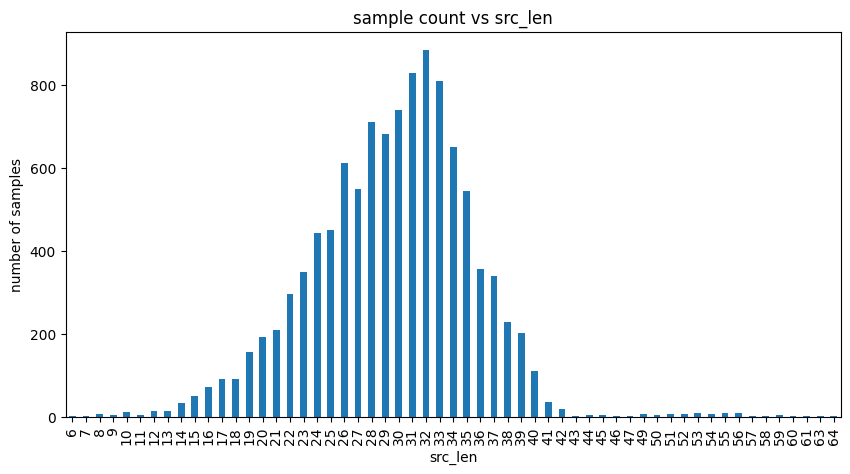

In [14]:
df_test.groupby("src_len")["correct"].count().plot(kind="bar",
                                                  figsize=(10, 5),
                                                  title="sample count vs src_len",
                                                  xlabel="src_len",
                                                  ylabel="number of samples")
plt.show()

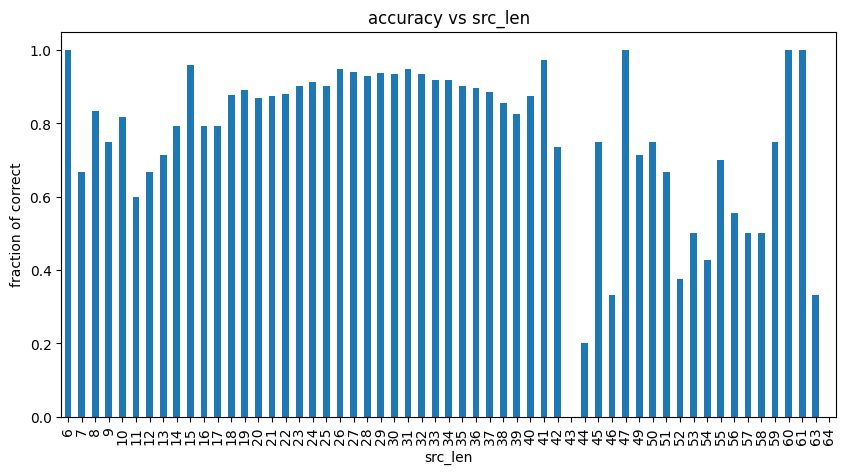

In [15]:
df_test.groupby("src_len")["correct"].mean().plot(kind="bar",
                                                  figsize=(10, 5),
                                                  title="accuracy vs src_len",
                                                  xlabel="src_len",
                                                  ylabel="fraction of correct")
plt.show()

**Select only those src_len where there are >= 100 samples:**

In [16]:
df_test.groupby("src_len").size() >= 100

src_len
6     False
7     False
8     False
9     False
10    False
11    False
12    False
13    False
14    False
15    False
16    False
17    False
18    False
19     True
20     True
21     True
22     True
23     True
24     True
25     True
26     True
27     True
28     True
29     True
30     True
31     True
32     True
33     True
34     True
35     True
36     True
37     True
38     True
39     True
40     True
41    False
42    False
43    False
44    False
45    False
46    False
47    False
49    False
50    False
51    False
52    False
53    False
54    False
55    False
56    False
57    False
58    False
59    False
60    False
61    False
63    False
64    False
dtype: bool

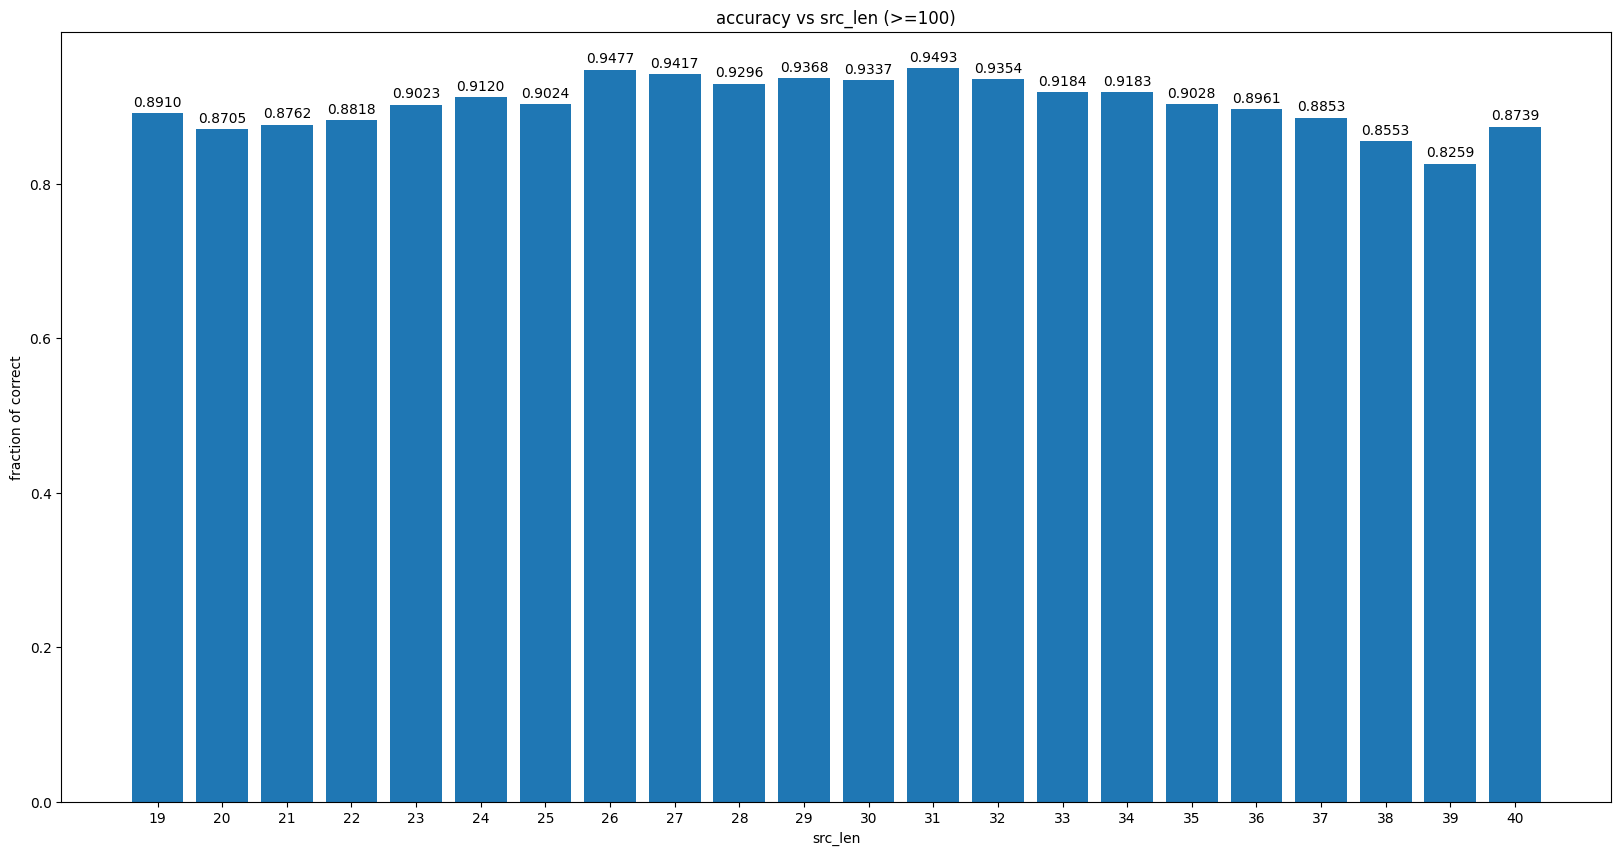

In [17]:
samples_more_eq_than = 100

mask = df_test.groupby("src_len").size() >= samples_more_eq_than

df_grouped = df_test.groupby("src_len")["correct"].mean()

df_masked = df_grouped[mask]

x, y = df_masked.index, df_masked.to_numpy()

plt.figure(figsize=(20, 10))

bars = plt.bar(x, y)

plt.bar_label(bars, fmt="%.4f", padding=3)

plt.xticks(x)
plt.title(f"accuracy vs src_len (>={samples_more_eq_than})")
plt.xlabel("src_len")
plt.ylabel("fraction of correct")

plt.show()

## 2. Performance dependence on nestedness (src_max_depth).

In [18]:
src_max_depth_vs_correct = df_test[["src_max_depth", "correct"]]

src_max_depth_vs_correct

,src_max_depth,correct
0,2,True
1,2,True
2,2,True
3,2,True
4,1,True
...,...,...
10880,2,False
10881,1,True
10882,1,True
10883,1,True


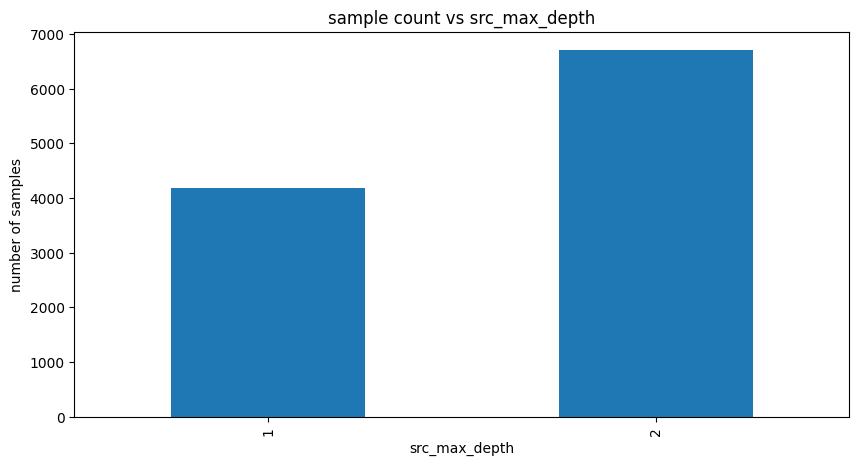

In [19]:
df_test.groupby("src_max_depth")["correct"].count().plot(kind="bar",
                                                  figsize=(10, 5),
                                                  title="sample count vs src_max_depth",
                                                  xlabel="src_max_depth",
                                                  ylabel="number of samples")
plt.show()

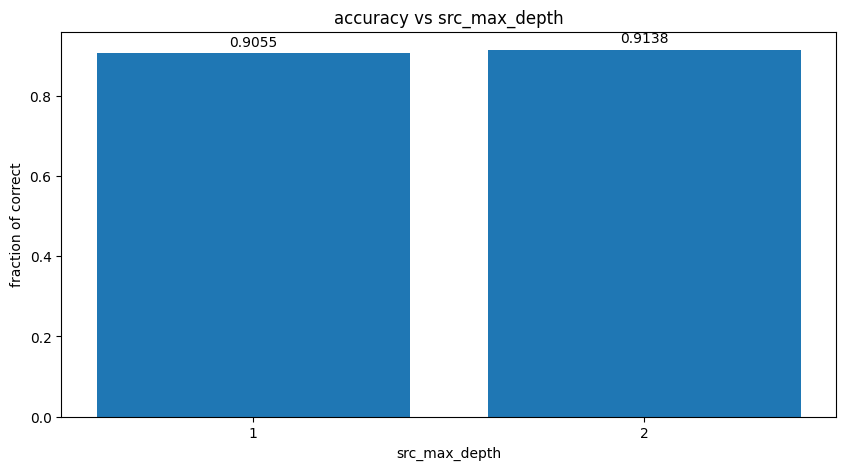

In [20]:
df_grouped_depth = df_test.groupby("src_max_depth")["correct"].mean()

x, y = df_grouped_depth.index, df_grouped_depth.to_numpy()

plt.figure(figsize=(10, 5))

bars = plt.bar(x, y)

plt.bar_label(bars, fmt="%.4f", padding=3)

plt.xticks(x)
plt.title(f"accuracy vs src_max_depth")
plt.xlabel("src_max_depth")
plt.ylabel("fraction of correct")

plt.show()

## 3. Performance dependence on the number of variables (src_n_vars).

In [21]:
src_n_vars_vs_correct = df_test[["src_n_vars", "correct"]]

src_n_vars_vs_correct

,src_n_vars,correct
0,3,True
1,2,True
2,2,True
3,2,True
4,2,True
...,...,...
10880,2,False
10881,2,True
10882,2,True
10883,2,True


In [22]:
df_test_var_count = df_test.groupby("src_n_vars")["correct"].count()

df_test_var_count

src_n_vars
2    10783
3      102
Name: correct, dtype: int64

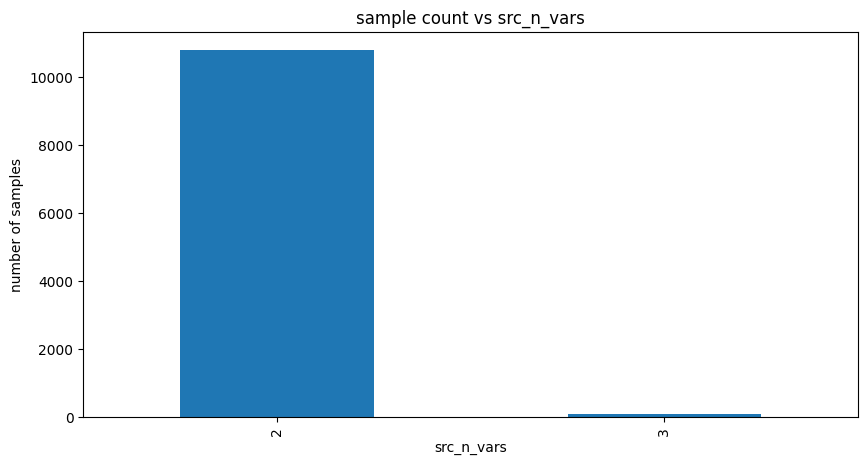

In [23]:
df_test_var_count.plot(kind="bar",
                      figsize=(10, 5),
                      title="sample count vs src_n_vars",
                      xlabel="src_n_vars",
                      ylabel="number of samples")
plt.show()

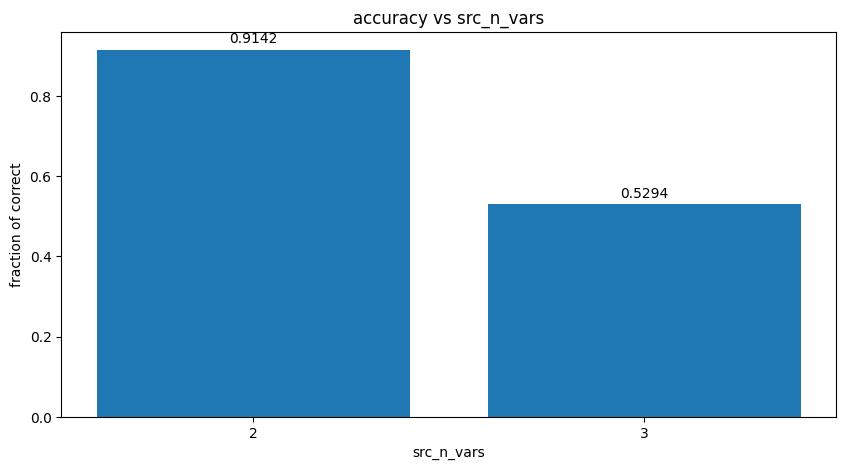

In [24]:
df_grouped_vars = df_test.groupby("src_n_vars")["correct"].mean()

x, y = df_grouped_vars.index, df_grouped_vars.to_numpy()

plt.figure(figsize=(10, 5))

bars = plt.bar(x, y)

plt.bar_label(bars, fmt="%.4f", padding=3)

plt.xticks(x)
plt.title(f"accuracy vs src_n_vars")
plt.xlabel("src_n_vars")
plt.ylabel("fraction of correct")

plt.show()

## 3. Performance dependence on the number of terms (src_n_terms).

In [25]:
src_n_terms_vs_correct = df_test[["src_n_terms", "correct"]]

src_n_terms_vs_correct

,src_n_terms,correct
0,6,True
1,5,True
2,5,True
3,5,True
4,5,True
...,...,...
10880,4,False
10881,6,True
10882,4,True
10883,6,True


In [26]:
df_test_terms_count = df_test.groupby("src_n_terms")["correct"].count()

df_test_terms_count

src_n_terms
1       1
2      32
3     406
4    2707
5    5003
6    2423
7     311
8       2
Name: correct, dtype: int64

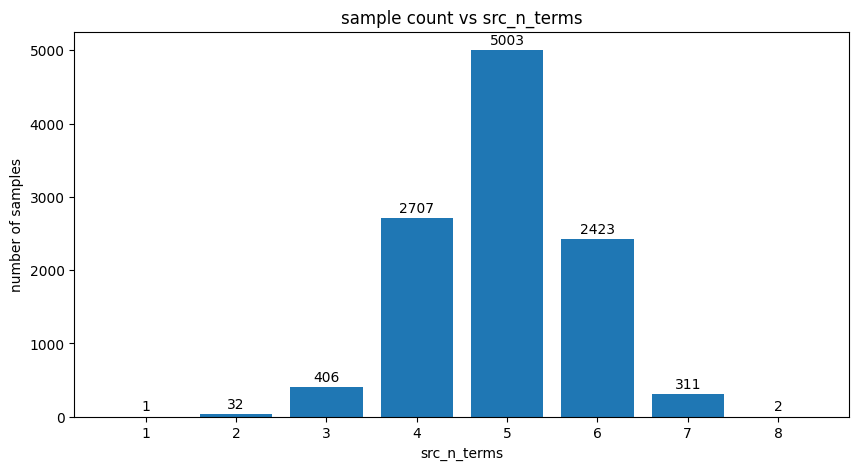

In [27]:
x, y = df_test_terms_count.index, df_test_terms_count.to_numpy()

plt.figure(figsize=(10, 5))

bars = plt.bar(x, y)

plt.bar_label(bars, padding=2)

plt.xticks(x)
plt.title(f"sample count vs src_n_terms")
plt.xlabel("src_n_terms")
plt.ylabel("number of samples")

plt.show()

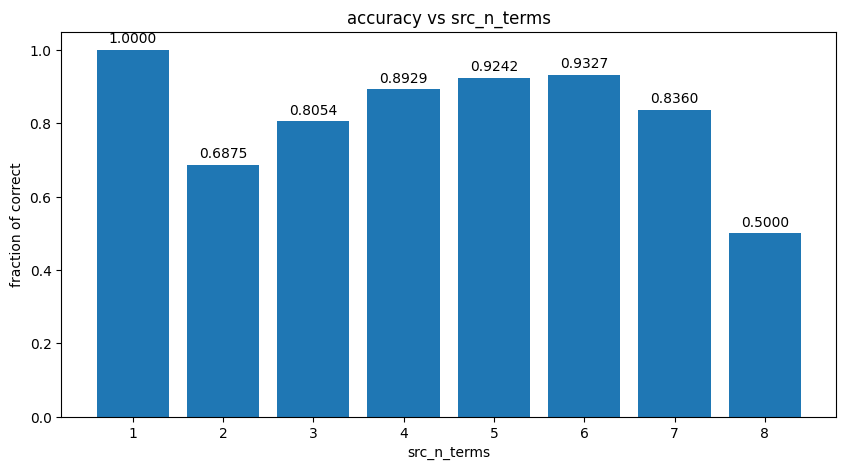

In [28]:
df_grouped_terms = df_test.groupby("src_n_terms")["correct"].mean()

x, y = df_grouped_terms.index, df_grouped_terms.to_numpy()

plt.figure(figsize=(10, 5))

bars = plt.bar(x, y)

plt.bar_label(bars, fmt="%.4f", padding=3)

plt.xticks(x)
plt.title(f"accuracy vs src_n_terms")
plt.xlabel("src_n_terms")
plt.ylabel("fraction of correct")

plt.show()

## 4. Performance dependence on the maximal constant term (src_max_const).

In [29]:
src_max_const_vs_correct = df_test[["src_max_const", "correct"]]

src_max_const_vs_correct

,src_max_const,correct
0,2,True
1,0,True
2,2,True
3,5,True
4,2,True
...,...,...
10880,3,False
10881,3,True
10882,2,True
10883,3,True


In [30]:
df_test_const_count = df_test.groupby("src_max_const")["correct"].count()

df_test_const_count

src_max_const
0      783
1      694
2     5207
3     2757
4     1105
5      208
6       81
7       42
8        3
10       1
14       1
15       2
16       1
Name: correct, dtype: int64

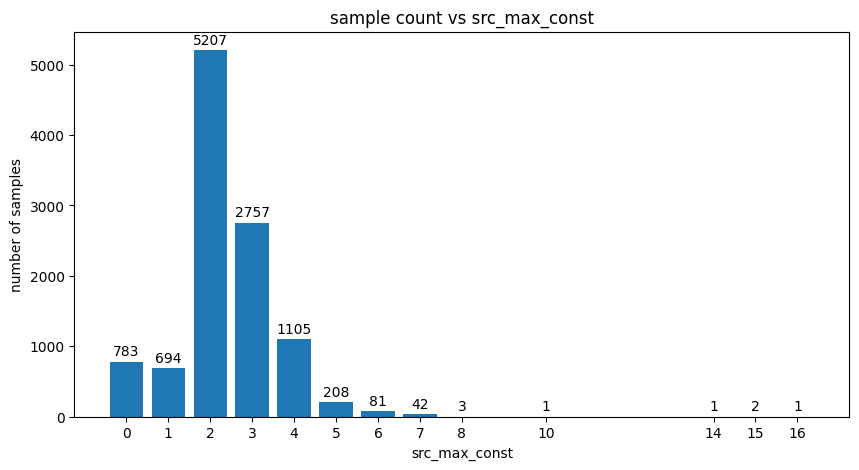

In [31]:
x, y = df_test_const_count.index, df_test_const_count.to_numpy()

plt.figure(figsize=(10, 5))

bars = plt.bar(x, y)

plt.bar_label(bars, padding=2)

plt.xticks(x)
plt.title(f"sample count vs src_max_const")
plt.xlabel("src_max_const")
plt.ylabel("number of samples")

plt.show()

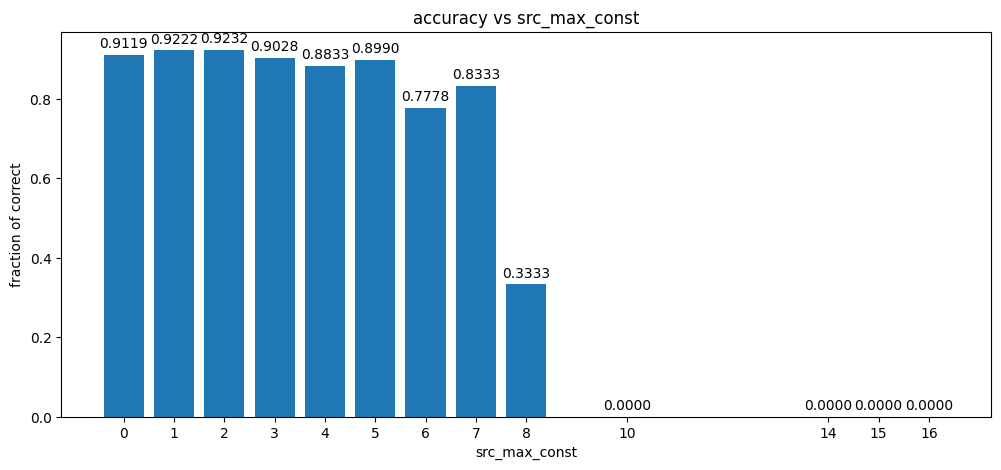

In [32]:
df_grouped_const = df_test.groupby("src_max_const")["correct"].mean()

x, y = df_grouped_const.index, df_grouped_const.to_numpy()

plt.figure(figsize=(12, 5))

bars = plt.bar(x, y)

plt.bar_label(bars, fmt="%.4f", padding=3)

plt.xticks(x)
plt.title(f"accuracy vs src_max_const")
plt.xlabel("src_max_const")
plt.ylabel("fraction of correct")

plt.show()

## 5. Performance dependence on the number of different operators (and, or, xor, not, add, sub, mul).

In [33]:
def make_plots_n_ops(src_n_op_name, df):
    fig, axs = plt.subplots(1, 2, figsize=(16, 5))

    fig.suptitle(f"Plots for {src_n_op_name.upper()}")
    
    df_count = df.groupby(src_n_op_name)["correct"].count()
    x_count, y_count = df_count.index, df_count.to_numpy()

    bars_count = axs[0].bar(x_count, y_count)
    axs[0].bar_label(bars_count, padding=2)
    axs[0].set_xticks(x_count)
    axs[0].set_xlabel(src_n_op_name)
    axs[0].set_ylabel("number of samples")
    axs[0].set_title(f'sample count vs {src_n_op_name}')


    df_acc = df.groupby(src_n_op_name)["correct"].mean()

    x_acc, y_acc = df_acc.index, df_acc.to_numpy()

    bars_acc = axs[1].bar(x_acc, y_acc)
    axs[1].bar_label(bars_acc, fmt="%.4f", padding=3)
    axs[1].set_xticks(x_acc)
    axs[1].set_xlabel(src_n_op_name)
    axs[1].set_ylabel("accuracy")
    axs[1].set_title(f'accuracy vs {src_n_op_name}')

    plt.tight_layout()
    plt.show()

In [34]:
operator_list = [
    "src_n_and",
    "src_n_or",
    "src_n_xor",
    "src_n_not",
    "src_n_add",
    "src_n_sub",
    "src_n_mul",
]

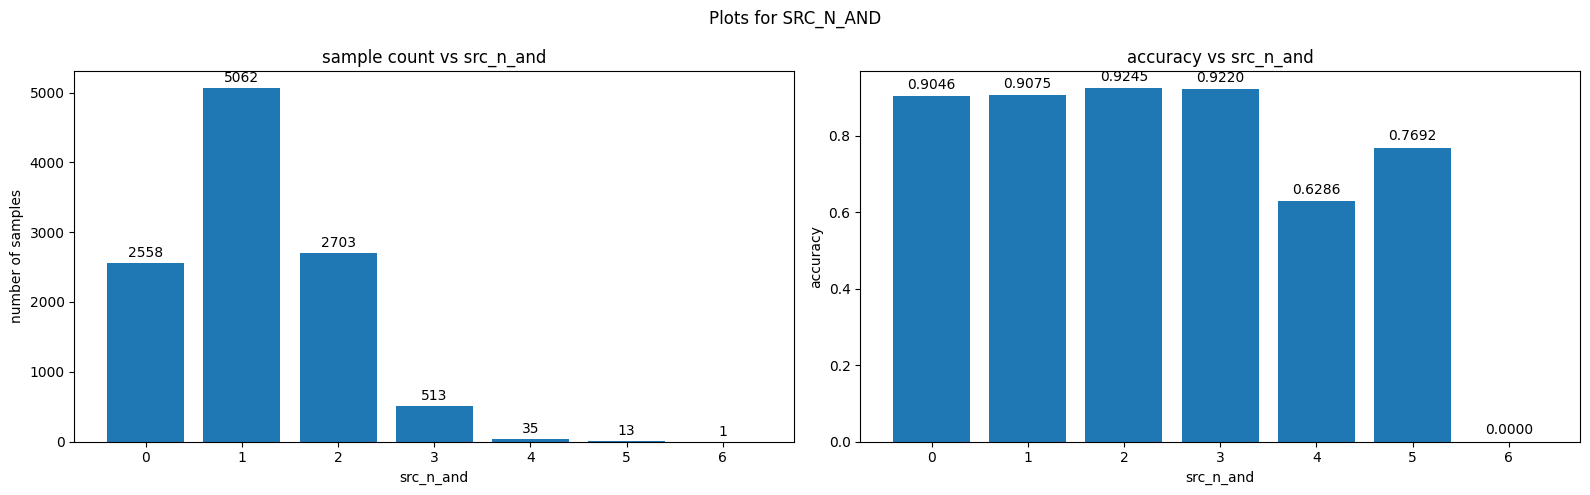

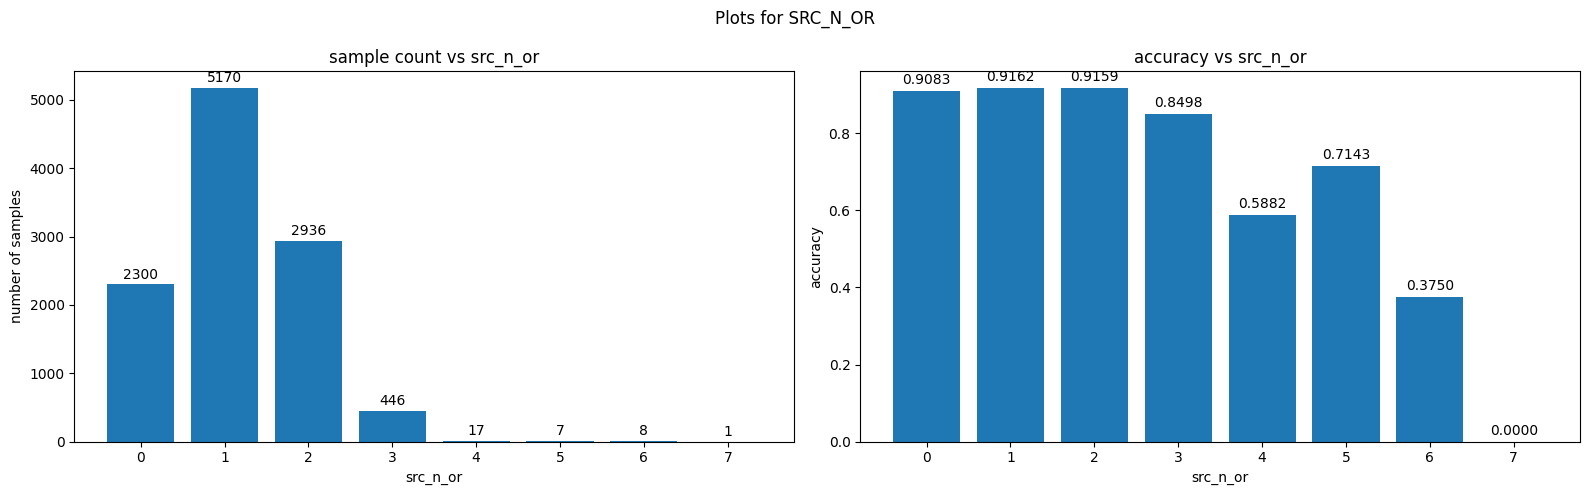

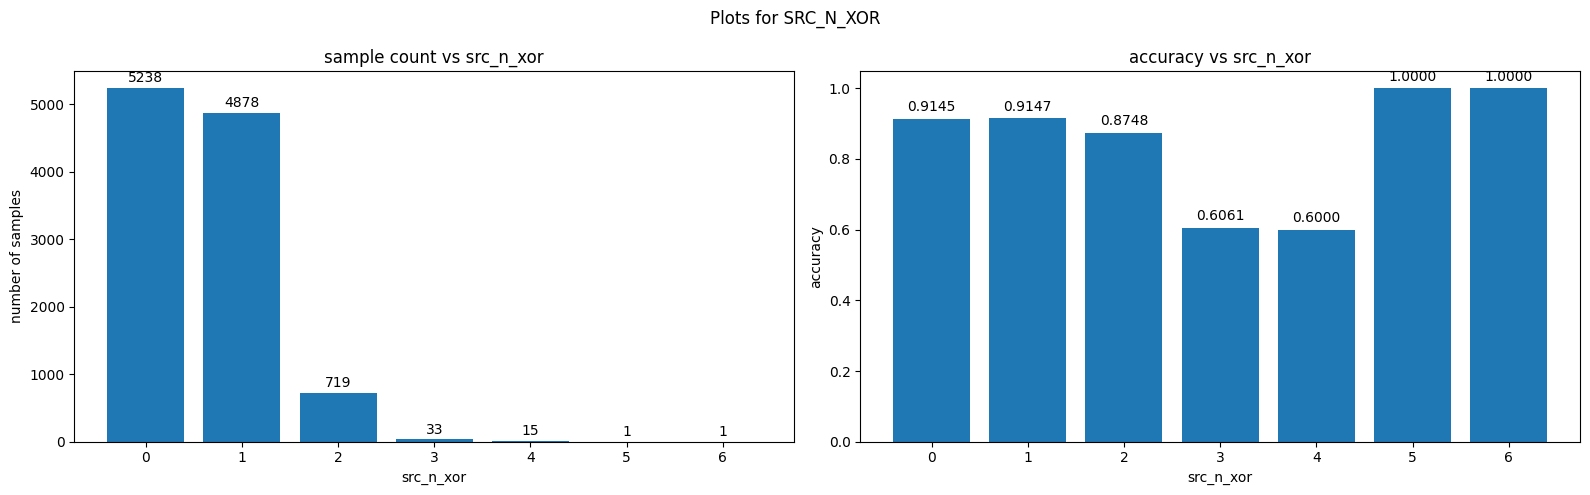

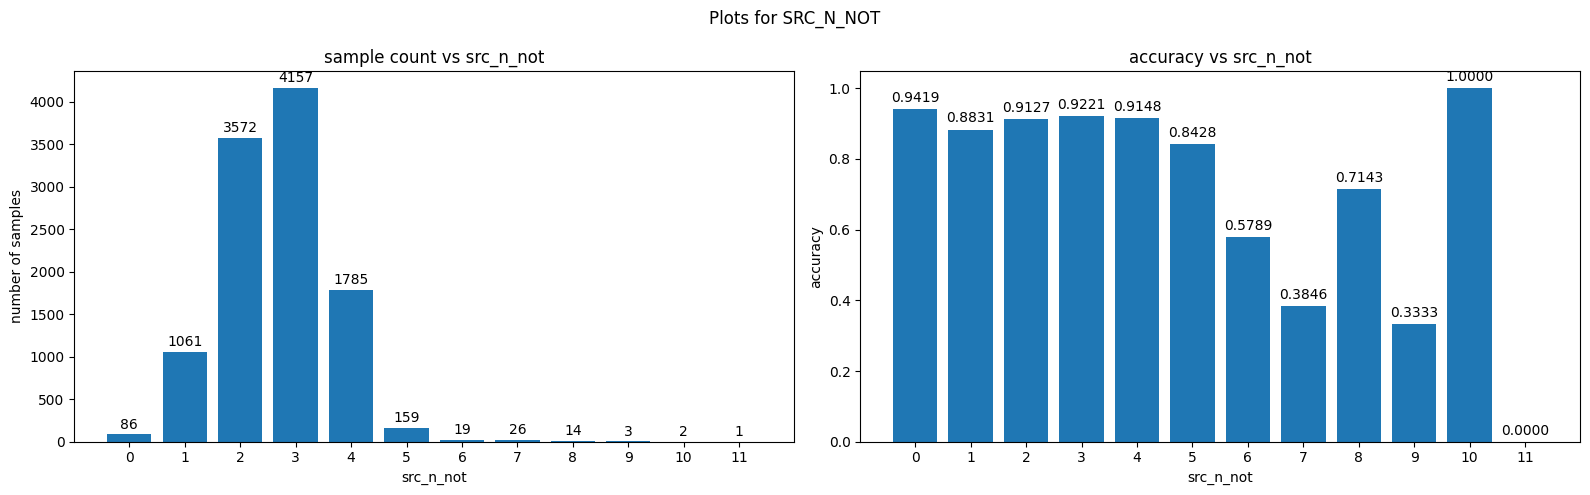

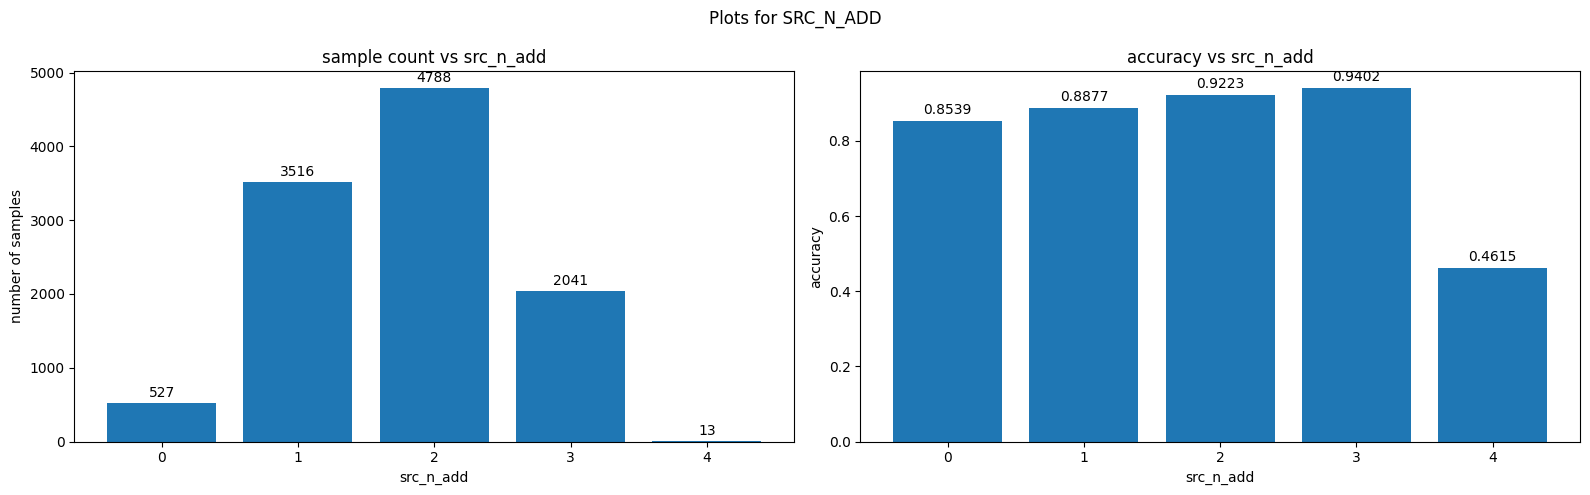

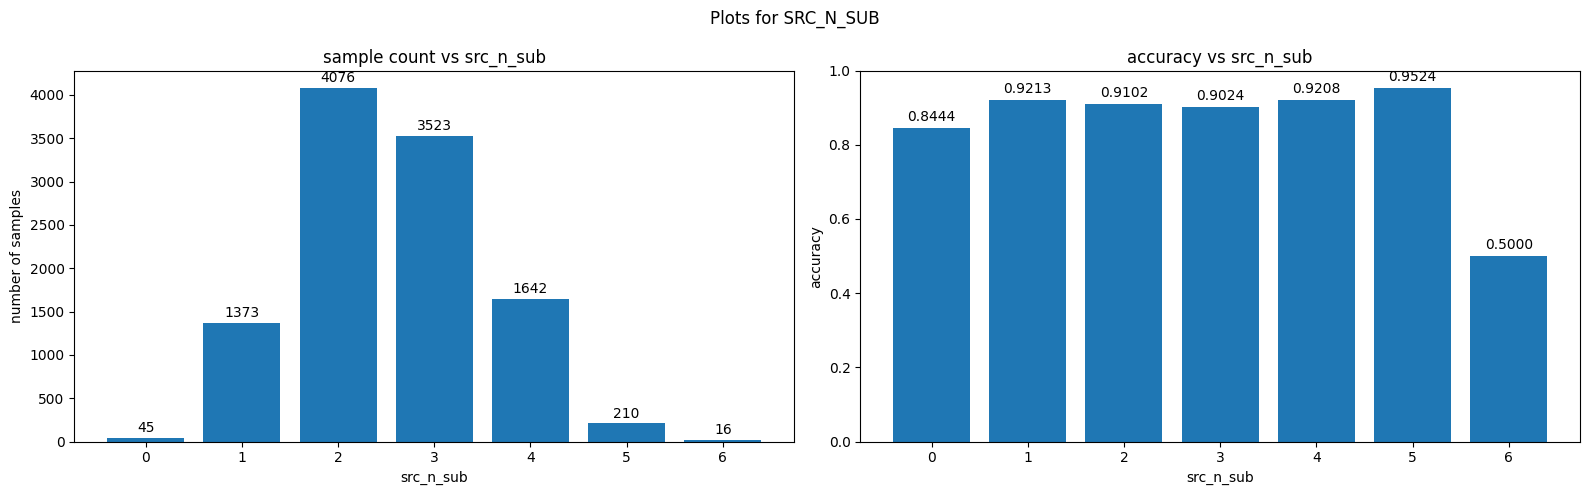

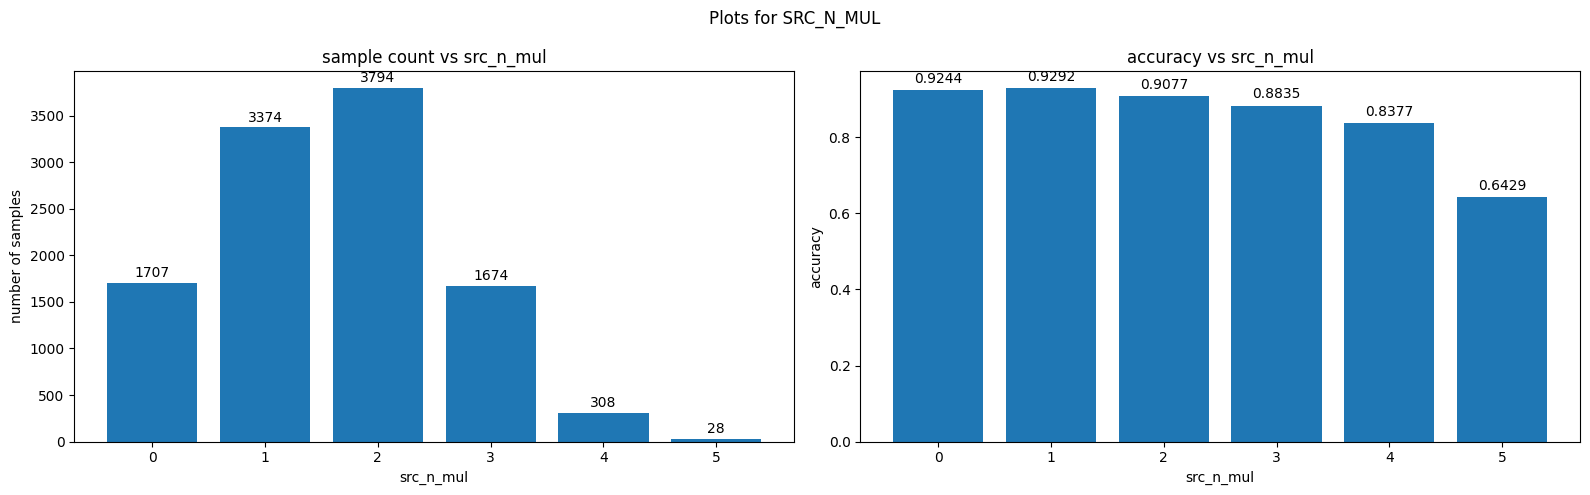

In [35]:
for operator in operator_list:
    make_plots_n_ops(operator, df_test)

### Heatmaps for combinations of 2 operators.

In [36]:
df_grouped_op_count = df_test.groupby(["src_n_xor", "src_n_not"])["correct"].count()
grid_count = df_grouped_op_count.unstack(fill_value=0)

grid_count

src_n_not,0,1,2,3,4,5,6,7,8,9,10,11
src_n_xor,,,,,,,,,,,,
0,39,491,1633,2012,975,81,0,3,3,1,0,0
1,47,529,1690,1813,729,59,3,5,2,0,1,0
2,0,41,249,330,74,4,5,9,5,1,0,1
3,0,0,0,1,7,11,5,4,3,1,1,0
4,0,0,0,1,0,4,4,5,1,0,0,0
5,0,0,0,0,0,0,1,0,0,0,0,0
6,0,0,0,0,0,0,1,0,0,0,0,0


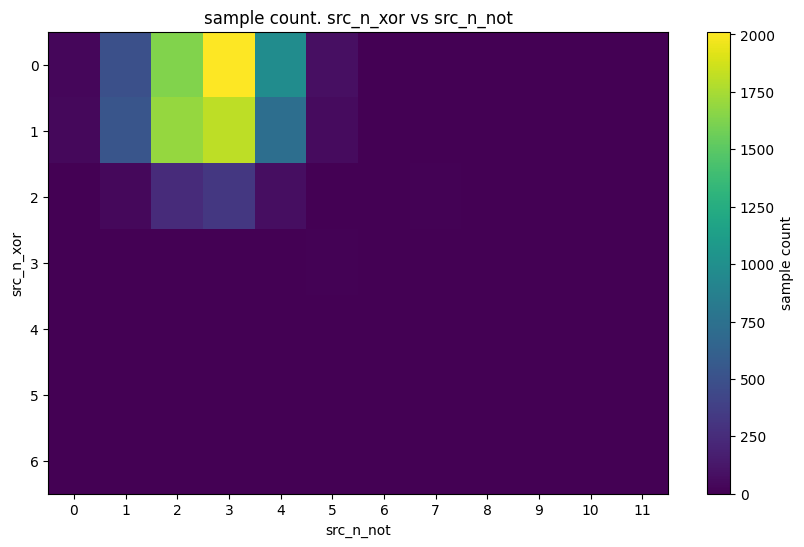

In [37]:
plt.figure(figsize=(10, 6))
plt.imshow(grid_count, aspect="auto")
plt.colorbar(label="sample count")

plt.xticks(range(len(grid_count.columns)), grid_count.columns)
plt.yticks(range(len(grid_count.index)), grid_count.index)
plt.xlabel("src_n_not")
plt.ylabel("src_n_xor")
plt.title("sample count. src_n_xor vs src_n_not")
plt.show()

In [38]:
df_grouped_op_acc = df_test.groupby(["src_n_xor", "src_n_not"])["correct"].mean()
grid_acc = df_grouped_op_acc.unstack(fill_value=0)

grid_acc.round(4)

src_n_not,0,1,2,3,4,5,6,7,8,9,10,11
src_n_xor,,,,,,,,,,,,
0,0.9487,0.8574,0.9057,0.9319,0.9262,0.8889,0.0000,0.3333,0.6667,0.0,0.0,0.0
1,0.9362,0.9055,0.9207,0.9156,0.9136,0.8305,0.6667,0.6000,1.0000,0.0,1.0,0.0
2,0.0000,0.9024,0.9036,0.9030,0.7973,0.5000,0.4000,0.2222,0.8000,0.0,0.0,0.0
3,0.0000,0.0000,0.0000,0.0000,0.7143,0.7273,0.6000,0.0000,0.6667,1.0,1.0,0.0
4,0.0000,0.0000,0.0000,0.0000,0.0000,0.7500,0.5000,0.8000,0.0000,0.0,0.0,0.0
5,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0,0.0,0.0
6,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0,0.0,0.0


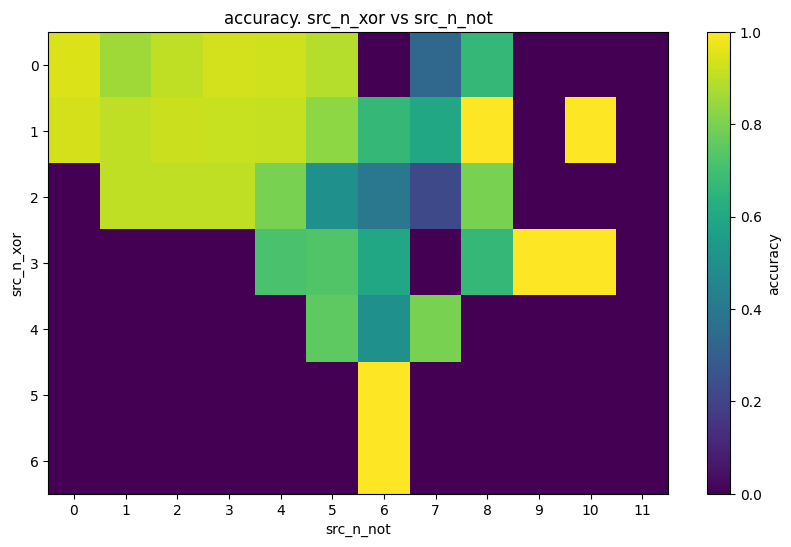

In [39]:
plt.figure(figsize=(10, 6))
plt.imshow(grid_acc, aspect="auto")
plt.colorbar(label="accuracy")

plt.xticks(range(len(grid_count.columns)), grid_count.columns)
plt.yticks(range(len(grid_count.index)), grid_count.index)
plt.xlabel("src_n_not")
plt.ylabel("src_n_xor")
plt.title("accuracy. src_n_xor vs src_n_not")
plt.show()